# 01 — Data overview

A quick look at the raw datasets (see `data/README.md`):

1. Twitter social ties between census tracts — Boston, Detroit, New York
2. ACS socioeconomic indicators — one row per census tract
3. Census tract and metro area geometries
4. Foursquare POIs — Boston, Detroit, New York

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import polars as pl
import matplotlib.pyplot as plt

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "../data/raw/"
PROCESSED = "../data/processed/"

# ── the three metro areas (cbsacode: name) ────────────────────────────────────
METROS = {14460: "Boston", 19820: "Detroit", 35620: "New York"}

## 1. Twitter social ties

Mutual-follower ties on Twitter, aggregated to pairs of census tracts by the inferred home location of the users.
- `tract_home1`, `tract_home2` — the two connected tracts (each pair appears once, `tract_home1 <= tract_home2`)
- `nr_ties` — number of mutual-follower ties between people living in the two tracts
- rows with `tract_home1 == tract_home2` are ties *within* a tract

In [2]:
# ── load ──────────────────────────────────────────────────────────────────────
ties = pd.read_csv(RAW + "twitter_tract_tract_edgelist.csv", sep=";")

# ── summary by metro ──────────────────────────────────────────────────────────
ties["within_tract"] = ties["tract_home1"] == ties["tract_home2"]
ties.groupby("cbsaname").agg(
    tract_pairs=("nr_ties", "size"),
    ties=("nr_ties", "sum"),
    within_tract_pairs=("within_tract", "sum"),
    max_ties=("nr_ties", "max"),
)

,tract_pairs,ties,within_tract_pairs,max_ties
cbsaname,,,,
Boston,22066,36914,511,86
Detroit,39501,59541,573,66
New York,91331,139700,1573,162


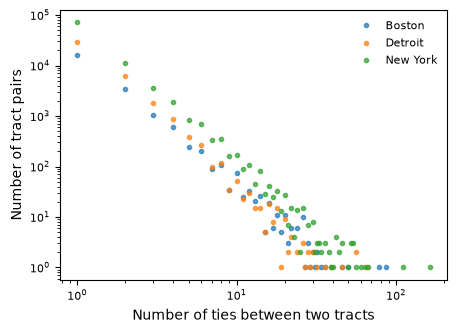

In [3]:
# ── distribution of tie weights ───────────────────────────────────────────────
# most tract pairs are connected by a single tie -- the distribution is heavy-tailed
fig, ax = plt.subplots(figsize=(5, 3.5))
for cbsaname, group in ties.groupby("cbsaname"):
    counts = group["nr_ties"].value_counts().sort_index()
    ax.loglog(counts.index, counts.values, "o", ms=3, alpha=0.7, label=cbsaname)

ax.set_xlabel("Number of ties between two tracts", fontsize=FS)
ax.set_ylabel("Number of tract pairs", fontsize=FS)
ax.tick_params(labelsize=FS2)
ax.legend(fontsize=FS2, frameon=False)

## 2. ACS socioeconomic indicators

Wide format: one column per variable and year, e.g. `income2019`.

**Note:** use **2019**. In the 2020 columns ~15% of tracts are missing (census tract boundaries were redrawn in 2020), while 2012–2019 are complete.

In [4]:
# ── load ──────────────────────────────────────────────────────────────────────
acs = pd.read_csv(RAW + "acs_data_census_tracts_2012_2020.csv.gz")

# ── missing values by year ────────────────────────────────────────────────────
print(f"Census tracts: {len(acs)}")
pd.DataFrame({
    year: acs[[f"population{year}", f"income{year}"]].isna().sum()
    for year in [2012, 2016, 2019, 2020]
})

Census tracts: 38788


,2012,2016,2019,2020
income2012,23.0,NaN,NaN,NaN
income2016,NaN,27.0,NaN,NaN
income2019,NaN,NaN,28.0,NaN
income2020,NaN,NaN,NaN,5704.0
population2012,0.0,NaN,NaN,NaN
population2016,NaN,0.0,NaN,NaN
population2019,NaN,NaN,0.0,NaN
population2020,NaN,NaN,NaN,5687.0


In [5]:
acs[["tract_id", "population2019", "income2019", "education_bachelor2019", "education_total2019",
     "race_total2019", "white2019", "black2019", "asian2019"]].head()

,tract_id,population2019,income2019,education_bachelor2019,education_total2019,race_total2019,white2019,black2019,asian2019
0,14000US34003001000,6765,82388.0,1921,4408,6765,5787,46,744
1,14000US34003002100,1547,92902.0,491,1132,1547,926,90,478
2,14000US34003002200,5487,45694.0,1375,3833,5487,3887,129,1370
3,14000US34003002300,5812,64084.0,1448,4223,5812,3905,31,1653
4,14000US34003003100,5545,33439.0,1171,3805,5545,3140,608,1369


## 3. Geometries

- `censustract_geoms_top50.geojson` has **one GeoJSON feature per line**, so `gpd.read_file()` would read only the first tract — we read it line by line.
- `metro_areas/` is in NAD83 (EPSG:4269), the tracts in WGS84 (EPSG:4326) — we convert before joining.
- A tract belongs to a metro if its representative point (a point guaranteed to be inside the polygon) is inside the metro boundary.

In [6]:
# ── census tracts ─────────────────────────────────────────────────────────────
with open(RAW + "censustract_geoms_top50.geojson") as f:
    features = [json.loads(line) for line in f]
tracts = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")

# ── metro areas ───────────────────────────────────────────────────────────────
metros = gpd.read_file(RAW + "metro_areas/metro_areas.shp").to_crs("EPSG:4326")
metros = metros[metros["cbsacode"].isin(METROS)]

# ── assign tracts to metros ───────────────────────────────────────────────────
points = gpd.GeoDataFrame(tracts[["full_geoid"]], geometry=tracts.representative_point(), crs="EPSG:4326")
points = gpd.sjoin(points, metros[["cbsacode", "geometry"]], predicate="within")
tracts = tracts.merge(points[["full_geoid", "cbsacode"]], on="full_geoid")

tracts.groupby("cbsacode").size().rename(index=METROS)

cbsacode
Boston      1007
Detroit     1301
New York    4542
dtype: int64

In [7]:
# ── how many Twitter ties can be matched to our tracts? ───────────────────────
# a few New York tracts lie outside the metro boundary file
for cbsacode, name in METROS.items():
    ids = set(tracts.loc[tracts["cbsacode"] == cbsacode, "full_geoid"])
    group = ties[ties["cbsacode"] == cbsacode]
    matched = group["tract_home1"].isin(ids) & group["tract_home2"].isin(ids)
    print(f"{name}: {matched.mean():.1%} of tract pairs matched")

Boston: 100.0% of tract pairs matched
Detroit: 100.0% of tract pairs matched
New York: 96.6% of tract pairs matched


(np.float64(-71.97758555),
 np.float64(-70.24370945000001),
 np.float64(41.465504200000005),
 np.float64(43.673133799999995))

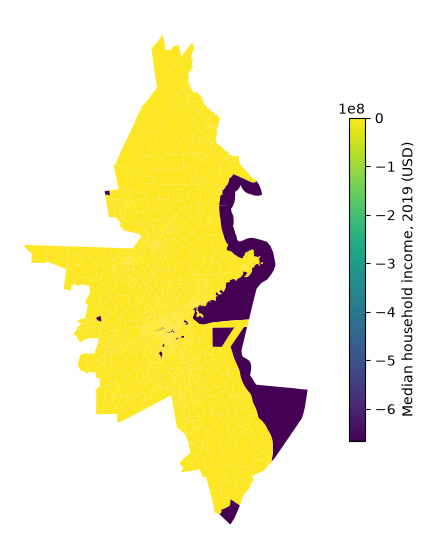

In [8]:
# ── map: median household income in Boston ────────────────────────────────────
boston = tracts[tracts["cbsacode"] == 14460].merge(
    acs[["tract_id", "income2019"]], left_on="full_geoid", right_on="tract_id"
)

fig, ax = plt.subplots(figsize=(7, 7))
boston.plot(column="income2019", cmap="viridis", legend=True, ax=ax,
            legend_kwds={"label": "Median household income, 2019 (USD)", "shrink": 0.6})
ax.axis("off")

**NYC PUMAs** (Public Use Microdata Areas) — larger statistical areas (~100k people), useful if you want to aggregate tracts into bigger neighborhoods in New York.

NYC PUMAs: 336


(np.float64(-80.956969),
 np.float64(-71.340373),
 np.float64(38.4772966),
 np.float64(45.327225399999996))

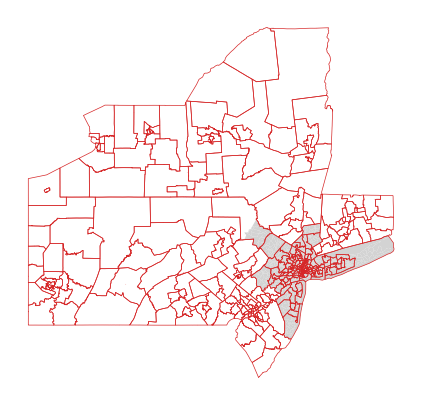

In [9]:
# ── NYC PUMAs ─────────────────────────────────────────────────────────────────
nyc_puma = gpd.read_file(RAW + "nyc_puma_all.geojson").to_crs("EPSG:4326")
print(f"NYC PUMAs: {len(nyc_puma)}")

fig, ax = plt.subplots(figsize=(7, 5))
tracts[tracts["cbsacode"] == 35620].plot(ax=ax, color="lightgrey", linewidth=0)
nyc_puma.boundary.plot(ax=ax, color="tab:red", linewidth=0.5)
ax.axis("off")

## 4. Foursquare POIs

Raw Foursquare Open Source Places for the three metros (~2.2 million POIs). The file is large, so we read only the columns we need with `polars`.

In [10]:
# ── load selected columns ─────────────────────────────────────────────────────
pois = pl.read_parquet(
    RAW + "places_US_newyork_boston_detroit.parquet",
    columns=["fsq_place_id", "name", "latitude", "longitude", "date_closed", "fsq_category_labels"],
)

print(f"POIs: {len(pois)}")
print(f"closed: {pois['date_closed'].is_not_null().mean():.1%}, no category: {pois['fsq_category_labels'].is_null().mean():.1%}")
pois.head()

POIs: 2247789
closed: 13.0%, no category: 8.0%


fsq_place_id,name,latitude,longitude,date_closed,fsq_category_labels
str,str,f64,f64,str,list[str]
"""50fc1810b0ed17da6bd0acf2""","""Widow's Walk - Winter Dog Walk""",42.17716,-70.736688,null,"[""Landmarks and Outdoors > Park > Dog Park""]"
"""5211bc3361fca3c6721d41ec""","""Fake Venue""",40.699836,-73.99368,"""2013-10-29""",null
"""67370ad7d04349d86049d4b8""","""Garylin Togs""",40.655109,-74.177452,null,"[""Business and Professional Services > Advertising Agency"", ""Retail > Fashion Retail > Clothing Store""]"
"""4cceefebdd919eb07f6d149e""","""Voting at PS 233""",40.65163,-73.914272,"""2010-11-01""","[""Community and Government > Polling Place""]"
"""553391ba498e14c3cd0cc628""","""NYRR Women's Half Marathon""",40.772262,-73.976675,"""2015-04-20""","[""Sports and Recreation""]"
